# Comparing Methods with Simulated Data
Compare alternate methodology for estimating gene prevalence under the Bernoulli model.
These experiments all use simulated data that follows model assumptions (i.e. case in 
which model is well-specified).

For each approach, we calculate MSE on the full set of simulated genes, as well as subsets of the pangenome:
- Core (present in 100% of genomes)
- Flexible (missing in at least one genome)
- Extended core (present in >=90% genomes)
- Shell (present in between 15% and 90% of genomes)
- Cloud (present in <=15% of genomes)

These categorical definitions come from [Maistrenko et al. (2020)](https://doi.org/10.1038/s41396-020-0600-z) 
and [Dmitrijeva et al. (2024)](https://doi.org/10.1038/s41559-024-02357-0)

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from gene_prevalence import BernoulliPrevalenceModel
from gene_prevalence.simulations import build_observed_data_matrix, \
    build_presence_absence_matrix, build_three_part_pi_vector

# instatiate random number generator with fixed seed for reproducibility
rng = np.random.default_rng(seed=9481)


In [2]:
# set aesthetic parameters

line_color = '#0F0A0A'    # dark

neutral_color = '#E0E0E0'

# thursday
accent_colors = ['#9B5DE5', '#FFAC69', '#00C9AE', '#FD3F92', '#0F0A0A', 
                 '#959AB1', '#FFDB66', '#63B9FF','#FFB1CA', '#4F1DD7']

style = {'axes.edgecolor': line_color,
         'axes.labelcolor': line_color,
         'text.color': line_color,
         'xtick.color': line_color,
         'ytick.color': line_color,
         'font.family': 'Helvetica',
         'font.Helvetica': ['Helvetica']}

palette = sns.color_palette(accent_colors)

sns.set_context('talk', rc={'lines.linewidth': 2})
sns.set_palette(palette)
sns.set_style('ticks', style)

plt.rcParams['legend.frameon'] = False
plt.rcParams['axes.spines.left'] = True
plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.bottom'] = True
plt.rcParams['axes.facecolor'] = 'none'
plt.rcParams['figure.facecolor'] = 'none'
plt.rcParams['patch.linewidth'] = 0
plt.rcParams['patch.edgecolor'] = 'none'
plt.rcParams['savefig.dpi'] = 300

### Generate simulated data
Generate ground truth simulated data

In [3]:
# build simulated data that matches model assumptions

n_genomes = 1000
n_genes = 10000

# # generate true pi values for all genes in the pangenome, with a three-part structure
# genes_per_genome = 3000
# n_core_genes = 800
# pi_vector_true = build_three_part_pi_vector(
#     pangenome_size=n_genes, 
#     genes_per_genome=genes_per_genome, 
#     n_core_genes=n_core_genes, 
#     non_core_span=(0.05, 1.0)
#     )

# generate true pi values for all genes in the pangenome, using a beta distribution
pi_vector_true = np.clip(rng.beta(a=0.2, b=0.5, size=n_genes) * 1.06, 0, 1)

# build a presence-absence matrix based on the true pi values
presence_absence_matrix = build_presence_absence_matrix(
    pi_vector=pi_vector_true, 
    n_genomes=n_genomes, 
    n_genes=n_genes,
    rng=rng
    )
print("Mean genes per genome:", round(presence_absence_matrix.sum(axis=1).mean()))

# generate completeness values for each genome, with a subset being complete
completeness_vector = pd.Series(
    np.clip(rng.uniform(low=0.05, high=1.1, size=n_genomes), 0, 1), 
    index=presence_absence_matrix.index
    )
print("N complete simulated genomes:", (completeness_vector == 1).sum())
print("N incomplete simulated genomes:", (completeness_vector < 1).sum())

# build an observed data matrix by simulating the observation process with no 
# gene-specific biases and not enforcing completeness (i.e. simulating each gene 
# observation as an independent Bernoulli trial)
observed_data_matrix, observation_mask = build_observed_data_matrix(
    presence_absence_matrix=presence_absence_matrix,
    completeness_levels=completeness_vector,
    rng=rng, 
    return_observation_mask=True
    )

observed_data_matrix


Mean genes per genome: 2973
N complete simulated genomes: 109
N incomplete simulated genomes: 891


,sim_gene_0,sim_gene_1,sim_gene_2,sim_gene_3,sim_gene_4,sim_gene_5,sim_gene_6,sim_gene_7,sim_gene_8,sim_gene_9,...,sim_gene_9990,sim_gene_9991,sim_gene_9992,sim_gene_9993,sim_gene_9994,sim_gene_9995,sim_gene_9996,sim_gene_9997,sim_gene_9998,sim_gene_9999
sim_genome_0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
sim_genome_1,0,0,0,0,0,1,0,0,0,0,...,0,1,1,1,0,0,0,1,0,0
sim_genome_2,0,0,0,0,0,1,1,0,0,0,...,0,0,0,0,0,0,0,1,0,0
sim_genome_3,0,0,0,0,0,0,0,0,0,0,...,1,0,0,0,0,0,0,1,0,1
sim_genome_4,0,0,0,0,0,1,0,0,0,0,...,0,1,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
sim_genome_995,0,0,0,0,0,1,0,0,0,0,...,1,1,0,1,0,0,0,1,0,1
sim_genome_996,0,0,0,0,0,1,1,0,0,0,...,1,1,0,1,0,0,0,1,0,0
sim_genome_997,0,0,0,1,0,1,0,0,0,0,...,1,0,0,1,0,0,0,0,0,1
sim_genome_998,0,0,0,1,0,1,0,0,0,0,...,1,0,0,0,0,0,0,1,0,1


In [4]:
# assign genes to pangenome categories based on their true pi values

true_pi_values = pd.Series(pi_vector_true, index=presence_absence_matrix.columns)
category_definitions = {
    'overall': true_pi_values.index, 
    'core': true_pi_values[true_pi_values == 1.0].index, 
    'extended_core': true_pi_values[true_pi_values >= 0.9].index,
    'flexible': true_pi_values[true_pi_values < 1.0].index,
    'shell': true_pi_values[(true_pi_values > 0.15) & (true_pi_values < 0.9)].index,
    'cloud': true_pi_values[true_pi_values <= 0.15].index
}

# print number of genes in each category
for category, genes in category_definitions.items():
    print(f"{category}: {len(genes)} genes")


overall: 10000 genes
core: 778 genes
extended_core: 1263 genes
flexible: 9222 genes
shell: 3277 genes
cloud: 5460 genes


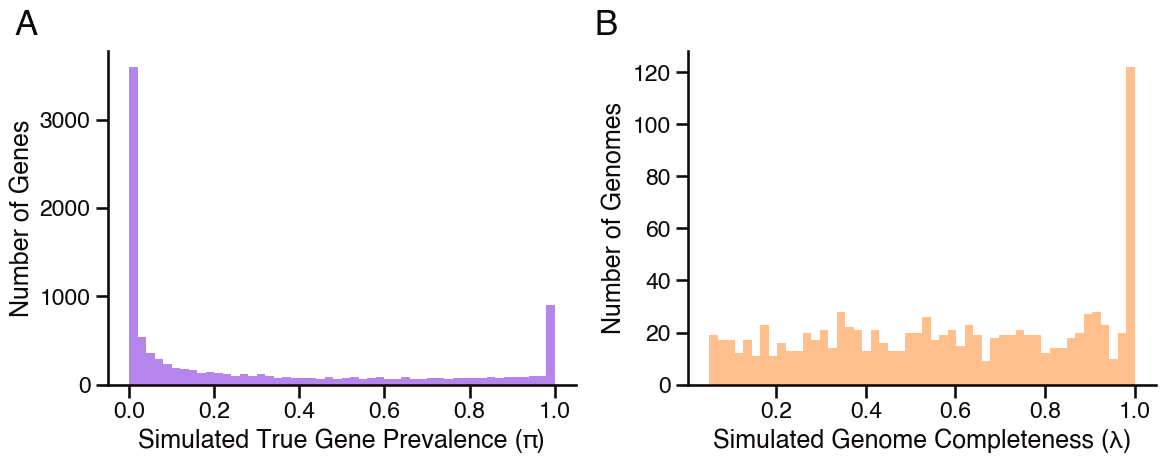

In [26]:
# plot distribution of true pi values and genome completeness values in simulated data

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.histplot(true_pi_values, bins=50, ax=axes[0], color=sns.color_palette()[0])
axes[0].set_xlabel("Simulated True Gene Prevalence (π)")
axes[0].set_ylabel("Number of Genes")
axes[0].annotate("A", xy=(-0.2, 1.05), xycoords='axes fraction', fontsize=25, fontweight='bold')
sns.histplot(completeness_vector, bins=50, ax=axes[1], color=sns.color_palette()[1])
axes[1].set_xlabel("Simulated Genome Completeness (λ)")
axes[1].set_ylabel("Number of Genomes")
axes[1].annotate("B", xy=(-0.2, 1.05), xycoords='axes fraction', fontsize=25, fontweight='bold')
plt.tight_layout()

### 1) Naive approach
Estimate gene prevalence as column means, without accounting for genome completeness

  method  gene_category  n_genes       mse
0  naive        overall    10000  0.037139
1  naive           core      778  0.170867
2  naive  extended_core     1263  0.164618
3  naive       flexible     9222  0.025857
4  naive          shell     3277  0.049265
5  naive          cloud     5460  0.000372


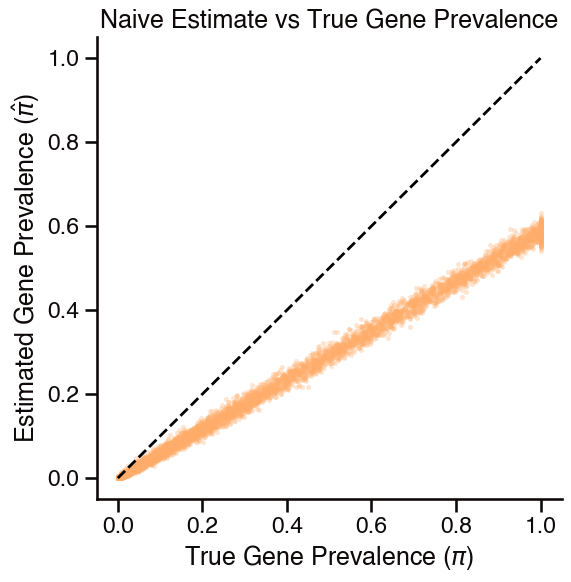

In [6]:
# estimate gene prevalence using naive approach (column means) and plot against true pi values

naive_pi_estimates = observed_data_matrix.mean(axis=0)

# calculate mse of naive estimates on full dataset and subset by gene category
results = []
for category, genes in category_definitions.items():
    mse = np.mean((naive_pi_estimates[genes] - true_pi_values[genes]) ** 2)
    results.append({
        'method': 'naive',
        'gene_category': category,
        'n_genes': len(genes),
        'mse': mse
    })
mse_df = pd.DataFrame(results, columns=['method', 'gene_category', 'n_genes', 'mse'])
print(mse_df[mse_df['method'] == 'naive'])

# build scatterplot of naive estimates vs true pi values
fig, ax = plt.subplots(figsize=(6, 6))
sns.scatterplot(
    x=pi_vector_true, 
    y=naive_pi_estimates, 
    color=sns.color_palette()[1],
    alpha=0.3,
    s=10,
    edgecolor=None,
    ax=ax
)
plt.xlabel(r"True Gene Prevalence ($\pi$)")
plt.ylabel(r"Estimated Gene Prevalence ($\hat{\pi}$)")
plt.title('Naive Estimate vs True Gene Prevalence')
# add diagonal line for reference
lims = [0, 1]
ax.plot(lims, lims, 'k--', zorder=1)
plt.show()


### 2) Subset approach
Estimate gene prevalence using only the complete genomes

    method  gene_category  n_genes       mse
6   subset        overall    10000  0.000752
7   subset           core      778  0.000000
8   subset  extended_core     1263  0.000144
9   subset       flexible     9222  0.000815
10  subset          shell     3277  0.001875
11  subset          cloud     5460  0.000218
There are 2838 genes not detected in any complete genome.


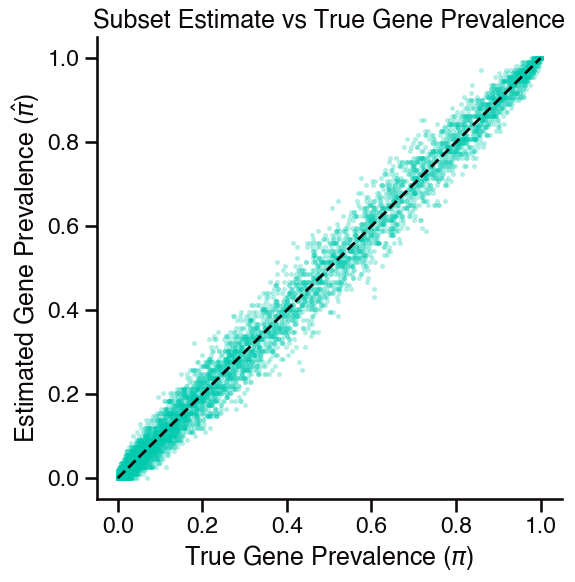

In [7]:
# estimate gene prevalence using subsetting approach (limit data to complete genomes) 
# and plot against true pi values

subset_pi_estimates = observed_data_matrix.loc[completeness_vector == 1].mean(axis=0)

# calculate mse of subset estimates on full dataset and subset by gene category
for category, genes in category_definitions.items():
    mse = np.mean((subset_pi_estimates[genes] - true_pi_values[genes]) ** 2)
    results.append({
        'method': 'subset',
        'gene_category': category,
        'n_genes': len(genes),
        'mse': mse
    })
mse_df = pd.DataFrame(results, columns=['method', 'gene_category', 'n_genes', 'mse'])
print(mse_df[mse_df['method'] == 'subset'])
print(f"There are {((subset_pi_estimates == 0).sum())} genes not detected in any complete genome.")

# build scatterplot of subset estimates vs true pi values
fig, ax = plt.subplots(figsize=(6, 6))
sns.scatterplot(
    x=pi_vector_true, 
    y=subset_pi_estimates, 
    color=sns.color_palette()[2],
    alpha=0.3,
    s=10,
    edgecolor=None,
    ax=ax
)
plt.xlabel(r"True Gene Prevalence ($\pi$)")
plt.ylabel(r"Estimated Gene Prevalence ($\hat{\pi}$)")
plt.title('Subset Estimate vs True Gene Prevalence')
# add diagonal line for reference
lims = [0, 1]
ax.plot(lims, lims, 'k--', zorder=1)
plt.show()

### 3) Unbiased estimator
Estimate gene prevalence using unbiased estimation, in combination with Chebychev method
for estimating confidence intervals. 

      method  gene_category  n_genes       mse
12  unbiased        overall    10000  0.000509
13  unbiased           core      778  0.000922
14  unbiased  extended_core     1263  0.001077
15  unbiased       flexible     9222  0.000474
16  unbiased          shell     3277  0.001019
17  unbiased          cloud     5460  0.000072


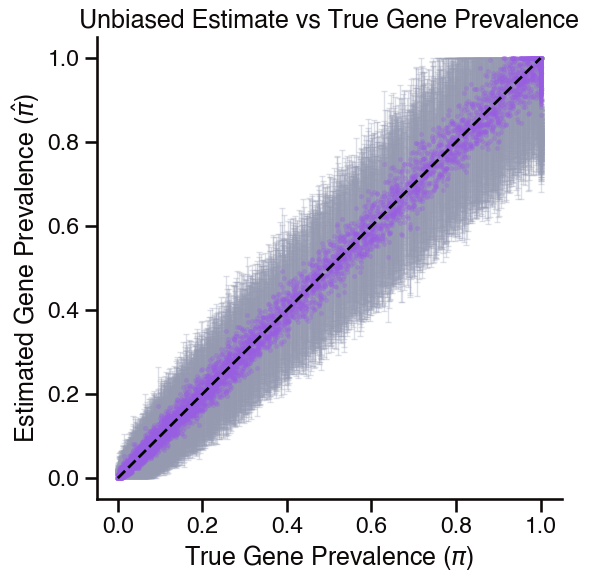

In [8]:
# estimate gene prevalence using unbiased estimator and plot against true pi values

# fit model to simulated dataset
model = BernoulliPrevalenceModel(
    data=observed_data_matrix,
    lambdas=completeness_vector,
)
fit = model.fit(
    estimator="unbiased",
    interval_method="chebyshev",
    alpha=0.05,
    clip=True,
)
pi_hat = fit.prevalence
ci_lower, ci_upper = fit.confidence_interval()  # 95% confidence intervals

# pull results together into a dataframe
unbiased_estimates_df = pd.DataFrame(
    {
        "pi_true": pi_vector_true,
        "pi_hat": pi_hat, 
        "ci_95_upper": ci_upper,
        "ci_95_lower": ci_lower,
    }
)

# calculate mse of unbiased estimates on full dataset and subset by gene category
for category, genes in category_definitions.items():
    mse = np.mean((unbiased_estimates_df.loc[genes, "pi_hat"] - unbiased_estimates_df.loc[genes, "pi_true"]) ** 2)
    results.append({
        'method': 'unbiased',
        'gene_category': category,
        'n_genes': len(genes),
        'mse': mse
    })
mse_df = pd.DataFrame(results, columns=['method', 'gene_category', 'n_genes', 'mse'])
print(mse_df[mse_df['method'] == 'unbiased'])

# build scatterplot of unbiased estimates vs true pi values
fig, ax = plt.subplots(figsize=(6, 6))
sns.scatterplot(
    x=unbiased_estimates_df["pi_true"], 
    y=unbiased_estimates_df["pi_hat"], 
    color=sns.color_palette()[0],
    alpha=0.3,
    s=10,
    edgecolor=None,
    ax=ax
)
plt.xlabel(r"True Gene Prevalence ($\pi$)")
plt.ylabel(r"Estimated Gene Prevalence ($\hat{\pi}$)")
plt.title('Unbiased Estimate vs True Gene Prevalence')
# add error bars for 95% confidence intervals
ax.errorbar(
    x=unbiased_estimates_df["pi_true"], 
    y=unbiased_estimates_df["pi_hat"], 
    yerr=[unbiased_estimates_df["pi_hat"] - unbiased_estimates_df["ci_95_lower"], 
          unbiased_estimates_df["ci_95_upper"] - unbiased_estimates_df["pi_hat"]],
    fmt='none',
    linewidth=1,
    capsize=2,
    ecolor=sns.color_palette()[5], 
    alpha=0.3,
    zorder=0
)
# add diagonal line for reference
lims = [0, 1]
ax.plot(lims, lims, 'k--', zorder=1)
plt.show()


### 4) MLE estimator
Estimate gene prevalence using Maximum Likelihood Estimator, in combination with 
likelihood ratios for estimating confidence intervals.

   method  gene_category  n_genes       mse
18    mle        overall    10000  0.000173
19    mle           core      778  0.000002
20    mle  extended_core     1263  0.000071
21    mle       flexible     9222  0.000188
22    mle          shell     3277  0.000430
23    mle          cloud     5460  0.000043


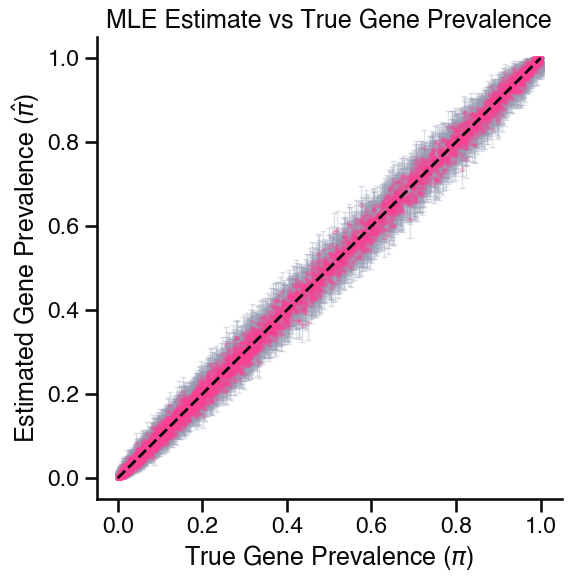

In [ ]:
# estimate gene prevalence using MLE estimator and plot against true pi values

# fit model to simulated dataset
fit = model.fit(
    estimator="mle",
    interval_method="likelihood_ratio",
    alpha=0.05,
    clip=True,
)
pi_hat = fit.prevalence
ci_lower, ci_upper = fit.confidence_interval()  # 95% confidence intervals

# pull results together into a dataframe
mle_estimates_df = pd.DataFrame(
    {
        "pi_true": pi_vector_true,
        "pi_hat": pi_hat, 
        "ci_95_upper": ci_upper,
        "ci_95_lower": ci_lower,
    }
)

# calculate mse of unbiased estimates on full dataset and subset by gene category
for category, genes in category_definitions.items():
    mse = np.mean((mle_estimates_df.loc[genes, "pi_hat"] - mle_estimates_df.loc[genes, "pi_true"]) ** 2)
    results.append({
        'method': 'mle',
        'gene_category': category,
        'n_genes': len(genes),
        'mse': mse
    })
mse_df = pd.DataFrame(results, columns=['method', 'gene_category', 'n_genes', 'mse'])
print(mse_df[mse_df['method'] == 'mle'])

# build scatterplot of MLE estimates vs true pi values
fig, ax = plt.subplots(figsize=(6, 6))
sns.scatterplot(
    x=mle_estimates_df["pi_true"], 
    y=mle_estimates_df["pi_hat"], 
    color=sns.color_palette()[3],
    alpha=0.3,
    s=10,
    edgecolor=None,
    ax=ax
)
plt.xlabel(r"True Gene Prevalence ($\pi$)")
plt.ylabel(r"Estimated Gene Prevalence ($\hat{\pi}$)")
plt.title('MLE Estimate vs True Gene Prevalence')
# add error bars for 95% confidence intervals
ax.errorbar(
    x=mle_estimates_df["pi_true"], 
    y=mle_estimates_df["pi_hat"], 
    yerr=[mle_estimates_df["pi_hat"] - mle_estimates_df["ci_95_lower"], 
          mle_estimates_df["ci_95_upper"] - mle_estimates_df["pi_hat"]],
    fmt='none',
    linewidth=1,
    capsize=2,
    ecolor=sns.color_palette()[5], 
    alpha=0.3,
    zorder=0
)
# add diagonal line for reference
lims = [0, 1]
ax.plot(lims, lims, 'k--', zorder=1)
plt.show()


# Compound figure

Make summary figure that combines all experiments

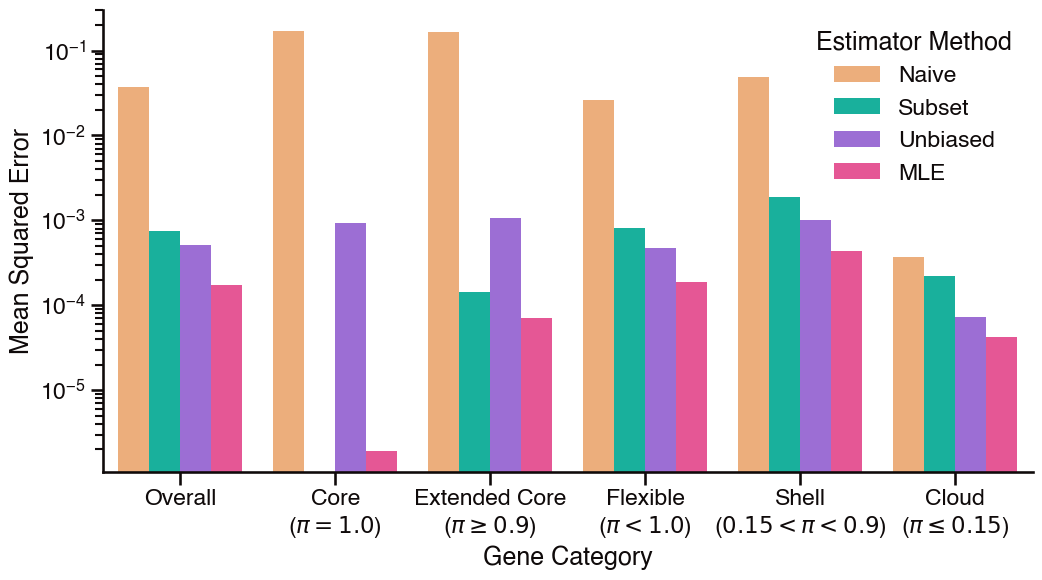

,method,gene_category,n_genes,mse,Gene Category,Method,Estimator Method
0,naive,overall,10000,0.037139,Overall,Naive,Naive
1,naive,core,778,0.170867,Core\n($\pi=1.0$),Naive,Naive
2,naive,extended_core,1263,0.164618,Extended Core\n($\pi\geq0.9$),Naive,Naive
3,naive,flexible,9222,0.025857,Flexible\n($\pi<1.0$),Naive,Naive
4,naive,shell,3277,0.049265,Shell\n($0.15<\pi<0.9$),Naive,Naive
5,naive,cloud,5460,0.000372,Cloud\n($\pi\leq0.15$),Naive,Naive
6,subset,overall,10000,0.000752,Overall,Subset,Subset
7,subset,core,778,0.000000,Core\n($\pi=1.0$),Subset,Subset
8,subset,extended_core,1263,0.000144,Extended Core\n($\pi\geq0.9$),Subset,Subset
9,subset,flexible,9222,0.000815,Flexible\n($\pi<1.0$),Subset,Subset


In [20]:
# plot MSE results for all methods and gene categories

# add gene category labels for plotting
mse_df['Gene Category'] = mse_df['gene_category'].map({
    'overall': 'Overall',
    'core': f"Core\n({r'$\pi=1.0$'})",
    'extended_core': f"Extended Core\n({r'$\pi\geq0.9$'})",
    'flexible': f"Flexible\n({r'$\pi<1.0$'})",
    'shell': f"Shell\n({r'$0.15<\pi<0.9$'})",
    'cloud': f"Cloud\n({r'$\pi\leq0.15$'})"
})

# add estimator method labels for plotting
mse_df['Estimator Method'] = mse_df['method'].map({
    'naive': 'Naive',
    'subset': 'Subset',
    'unbiased': 'Unbiased',
    'mle': 'MLE'
})

fig, ax = plt.subplots(figsize=(12, 6))
sns.barplot(
    data=mse_df, 
    x='Gene Category', 
    y='mse', 
    hue='Estimator Method', 
    ax=ax,
    palette=[sns.color_palette()[i] for i in [1, 2, 0, 3]]
)
ax.set_yscale('log')
ax.set_xlabel("Gene Category")
ax.set_ylabel("Mean Squared Error")
plt.show()

# show mse_df
mse_df

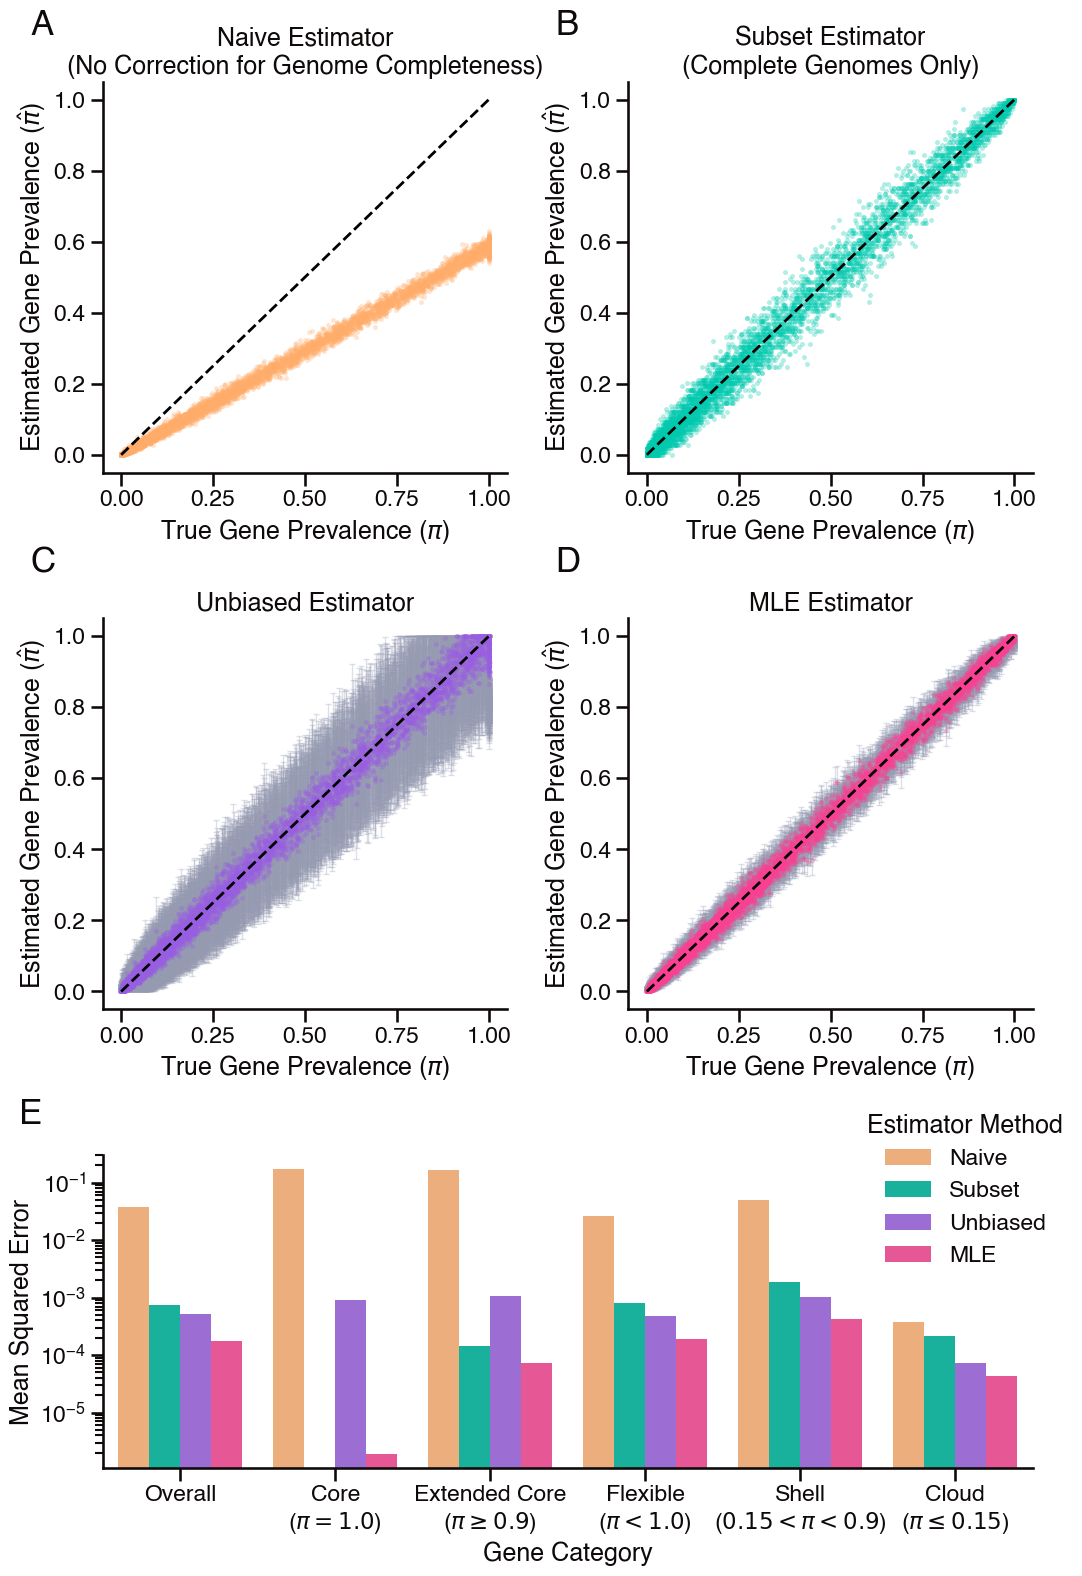

In [31]:
# combine all plots into a single publication-ready figure

# grid layout: 3 rows, 2 columns, bottom row for MSE barplot, top two rows for scatterplots of each method
fig = plt.figure(figsize=(12, 18))
gs = fig.add_gridspec(3, 2, height_ratios=[1, 1, 0.8], hspace=0.4, wspace=0.3)

# annotation specs
annotation_kwargs = dict(
    xy=(-0.18, 1.12),
    xycoords='axes fraction',
    fontsize=25,
    fontweight='bold'
)

# plot A: scatterplot of naive estimates vs true pi values
ax1 = fig.add_subplot(gs[0, 0])
sns.scatterplot(
    x=pi_vector_true, 
    y=naive_pi_estimates, 
    color=sns.color_palette()[1],
    alpha=0.3,
    s=10,
    edgecolor=None,
    ax=ax1
)
ax1.set_xlabel(r"True Gene Prevalence ($\pi$)")
ax1.set_ylabel(r"Estimated Gene Prevalence ($\hat{\pi}$)")
ax1.set_title('Naive Estimator\n(No Correction for Genome Completeness)')
# add diagonal line for reference
lims = [0, 1]
ax1.plot(lims, lims, 'k--', zorder=1)
# add annotation
ax1.annotate("A", **annotation_kwargs)

# plot B: scatterplot of subset estimates vs true pi values
ax2 = fig.add_subplot(gs[0, 1])
sns.scatterplot(
    x=pi_vector_true, 
    y=subset_pi_estimates, 
    color=sns.color_palette()[2],
    alpha=0.3,
    s=10,
    edgecolor=None,
    ax=ax2
)
ax2.set_xlabel(r"True Gene Prevalence ($\pi$)")
ax2.set_ylabel(r"Estimated Gene Prevalence ($\hat{\pi}$)")
ax2.set_title('Subset Estimator\n(Complete Genomes Only)')
# add diagonal line for reference
lims = [0, 1]
ax2.plot(lims, lims, 'k--', zorder=1)
# add annotation
ax2.annotate("B", **annotation_kwargs)

# plot C: scatterplot of unbiased estimates vs true pi values with error bars
ax3 = fig.add_subplot(gs[1, 0])
sns.scatterplot(
    x=unbiased_estimates_df["pi_true"], 
    y=unbiased_estimates_df["pi_hat"], 
    color=sns.color_palette()[0],
    alpha=0.3,
    s=10,
    edgecolor=None,
    ax=ax3
)
ax3.set_xlabel(r"True Gene Prevalence ($\pi$)")
ax3.set_ylabel(r"Estimated Gene Prevalence ($\hat{\pi}$)")
ax3.set_title('Unbiased Estimator')
# add error bars for 95% confidence intervals
ax3.errorbar(
    x=unbiased_estimates_df["pi_true"], 
    y=unbiased_estimates_df["pi_hat"], 
    yerr=[unbiased_estimates_df["pi_hat"] - unbiased_estimates_df["ci_95_lower"], 
          unbiased_estimates_df["ci_95_upper"] - unbiased_estimates_df["pi_hat"]],
    fmt='none',
    linewidth=1,
    capsize=2,
    ecolor=sns.color_palette()[5], 
    alpha=0.3,
    zorder=0
)
# add diagonal line for reference
lims = [0, 1]
ax3.plot(lims, lims, 'k--', zorder=1)
# add annotation
ax3.annotate("C", **annotation_kwargs)

# plot D: scatterplot of MLE estimates vs true pi values with error bars
ax4 = fig.add_subplot(gs[1, 1])
sns.scatterplot(
    x=mle_estimates_df["pi_true"], 
    y=mle_estimates_df["pi_hat"], 
    color=sns.color_palette()[3],
    alpha=0.3,
    s=10,
    edgecolor=None,
    ax=ax4
)
ax4.set_xlabel(r"True Gene Prevalence ($\pi$)")
ax4.set_ylabel(r"Estimated Gene Prevalence ($\hat{\pi}$)")
ax4.set_title('MLE Estimator')
# add error bars for 95% confidence intervals
ax4.errorbar(
    x=mle_estimates_df["pi_true"], 
    y=mle_estimates_df["pi_hat"], 
    yerr=[mle_estimates_df["pi_hat"] - mle_estimates_df["ci_95_lower"], 
          mle_estimates_df["ci_95_upper"] - mle_estimates_df["pi_hat"]],
    fmt='none',
    linewidth=1,
    capsize=2,
    ecolor=sns.color_palette()[5], 
    alpha=0.3,
    zorder=0
)
# add diagonal line for reference
lims = [0, 1]
ax4.plot(lims, lims, 'k--', zorder=1)
# add annotation
ax4.annotate("D", **annotation_kwargs)

# plot E: barplot of MSE results for all methods and gene categories
ax5 = fig.add_subplot(gs[2, :])
sns.barplot(
    data=mse_df, 
    x='Gene Category', 
    y='mse', 
    hue='Estimator Method', 
    ax=ax5,
    palette=[sns.color_palette()[i] for i in [1, 2, 0, 3]]
)
ax5.set_yscale('log')
ax5.set_ylabel("Mean Squared Error")
ax5.legend(title="Estimator Method", loc='upper left', bbox_to_anchor=(0.8, 1.2))
# add annotation
annotation_kwargs['xy'] = (-0.09, 1.1)
ax5.annotate("E", **annotation_kwargs)

# show and/or save figure
# fig.savefig("method_comparison_simulations_figure.png", bbox_inches='tight')
plt.show()


## Comparison of confidence intervals
Compare coverage and length of confidence intervals 

In [ ]:
# calculate CIs at different alpha levels for unbiased and MLE estimators

# set different alpha levels to test
alpha_values = np.array([0.01, 0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9])

# iterate through alpha values
results = []
for a in alpha_values:
    for estimator in ['unbiased', 'mle']:
        interval_method = "chebyshev" if estimator == "unbiased" else "likelihood_ratio"
        fit = model.fit(
            estimator=estimator,
            interval_method=interval_method,
            alpha=a,
            clip=True,
        )
        ci_lower, ci_upper = fit.confidence_interval()
        coverage = np.mean((ci_lower <= pi_vector_true) & (ci_upper >= pi_vector_true))

        # append results
        results.append({
            'estimator': estimator,
            'interval_method': interval_method,
            'significance_level': a,
            'confidence_level': 1 - a,
            'coverage': coverage
        })

# build dataframe of results
coverage_df = pd.DataFrame(results)
coverage_df

,estimator,interval_method,significance_level,confidence_level,coverage
0,unbiased,chebyshev,0.01,0.99,0.7991
1,mle,likelihood_ratio,0.01,0.99,0.9914
2,unbiased,chebyshev,0.05,0.95,0.7989
3,mle,likelihood_ratio,0.05,0.95,0.9605
4,unbiased,chebyshev,0.10,0.90,0.7972
5,mle,likelihood_ratio,0.10,0.90,0.9226
6,unbiased,chebyshev,0.20,0.80,0.7785
7,mle,likelihood_ratio,0.20,0.80,0.8375
8,unbiased,chebyshev,0.30,0.70,0.7482
9,mle,likelihood_ratio,0.30,0.70,0.7549
